In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42

In [ ]:
## 2. Load dataset and define target
The built-in scikit-learn dataset contains 569 records and 30 numeric predictors. The target is recoded so malignant is 1.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = (dataset.target == 0).astype(int)  # 0=benign, 1=malignant
y.name = "diagnosis_malignant"
df = X.copy()
df["diagnosis"] = y.map({0: "Benign", 1: "Malignant"})
print("Dataset shape:", X.shape)
display(df.head())

Dataset shape: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant


In [ ]:
## 3. Data quality checks

In [3]:
print("Missing predictor values:", int(X.isna().sum().sum()))
print("Duplicate predictor rows:", int(X.duplicated().sum()))
print("Data types:")
display(X.dtypes.value_counts().rename_axis("data_type").reset_index(name="columns"))
class_counts = df["diagnosis"].value_counts().reindex(["Benign", "Malignant"])
display(pd.DataFrame({"count": class_counts, "percentage": (class_counts/len(df)*100).round(2)}))

Missing predictor values: 0
Duplicate predictor rows: 0
Data types:


,data_type,columns
0,float64,30


,count,percentage
diagnosis,,
Benign,357,62.74
Malignant,212,37.26


In [ ]:
## 4. Descriptive statistics
The table includes count, mean, standard deviation, quartiles, minimum and maximum for every predictor.

In [4]:
descriptive_statistics = X.describe().T
descriptive_statistics["missing_values"] = X.isna().sum()
descriptive_statistics["unique_values"] = X.nunique()
display(descriptive_statistics.round(3))
descriptive_statistics.to_csv("part2_descriptive_statistics.csv")

,count,mean,std,min,25%,50%,75%,max,missing_values,unique_values
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110,0,456
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280,0,479
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500,0,522
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000,0,539
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163,0,474
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345,0,537
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427,0,537
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201,0,542
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304,0,432
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097,0,499


In [ ]:
## 5. EDA — diagnosis class distribution

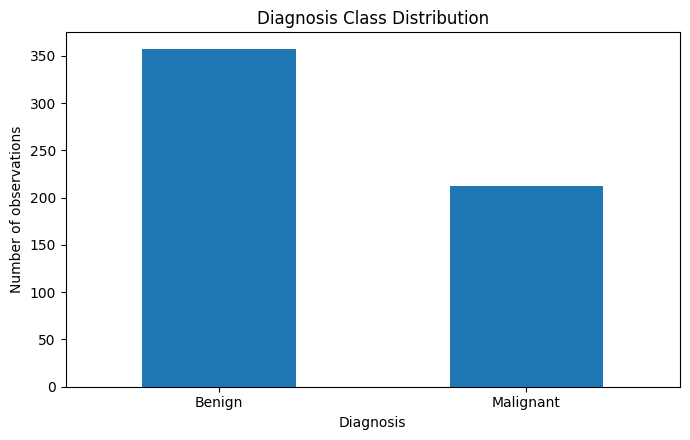

In [5]:
plt.figure(figsize=(7, 4.5))
class_counts.plot(kind="bar")
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis"); plt.ylabel("Number of observations")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [ ]:
## 6. EDA — feature distributions
Histograms show the shape and spread of representative mean and worst-value measurements. All 30 features are included in the descriptive-statistics table.

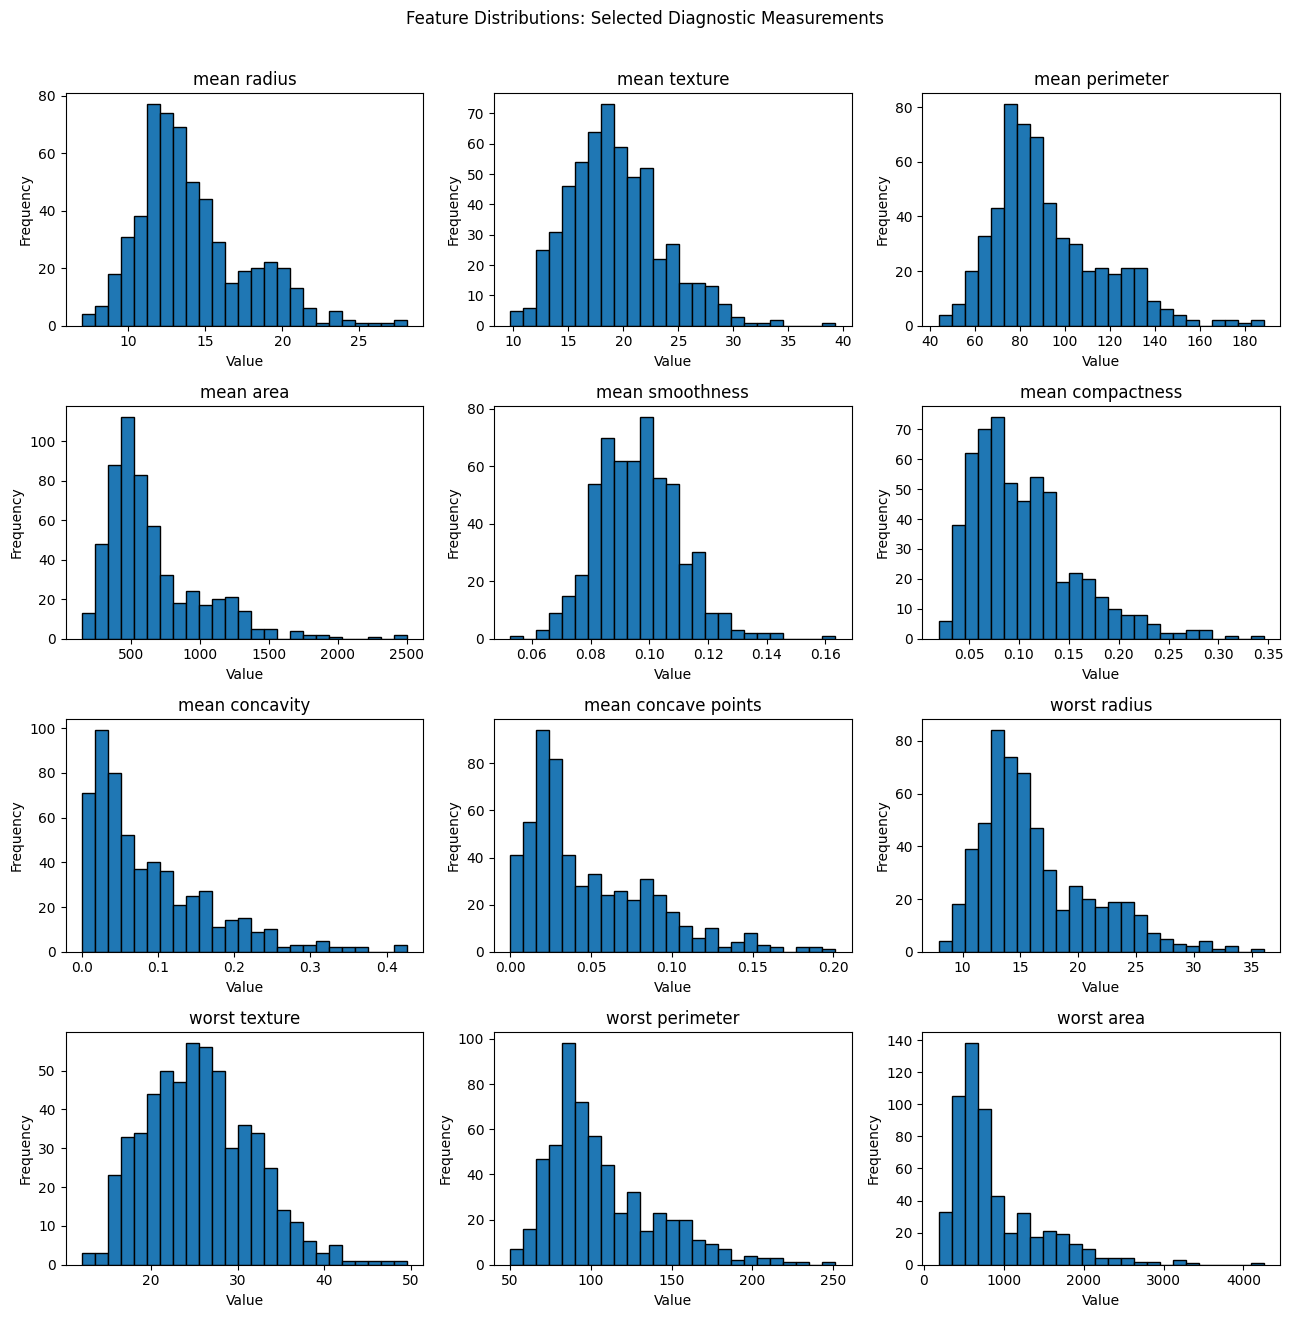

In [6]:
eda_features = ["mean radius", "mean texture", "mean perimeter", "mean area",
 "mean smoothness", "mean compactness", "mean concavity", "mean concave points",
 "worst radius", "worst texture", "worst perimeter", "worst area"]
fig, axes = plt.subplots(4, 3, figsize=(13, 13))
for ax, feature in zip(axes.ravel(), eda_features):
    ax.hist(X[feature], bins=25, edgecolor="black")
    ax.set_title(feature); ax.set_xlabel("Value"); ax.set_ylabel("Frequency")
fig.suptitle("Feature Distributions: Selected Diagnostic Measurements", y=1.01)
fig.tight_layout(); plt.show()

In [ ]:
## 7. EDA — feature boxplots by diagnosis
Differences in medians and spread may indicate useful patterns, but these plots do not establish that a single feature diagnoses cancer.

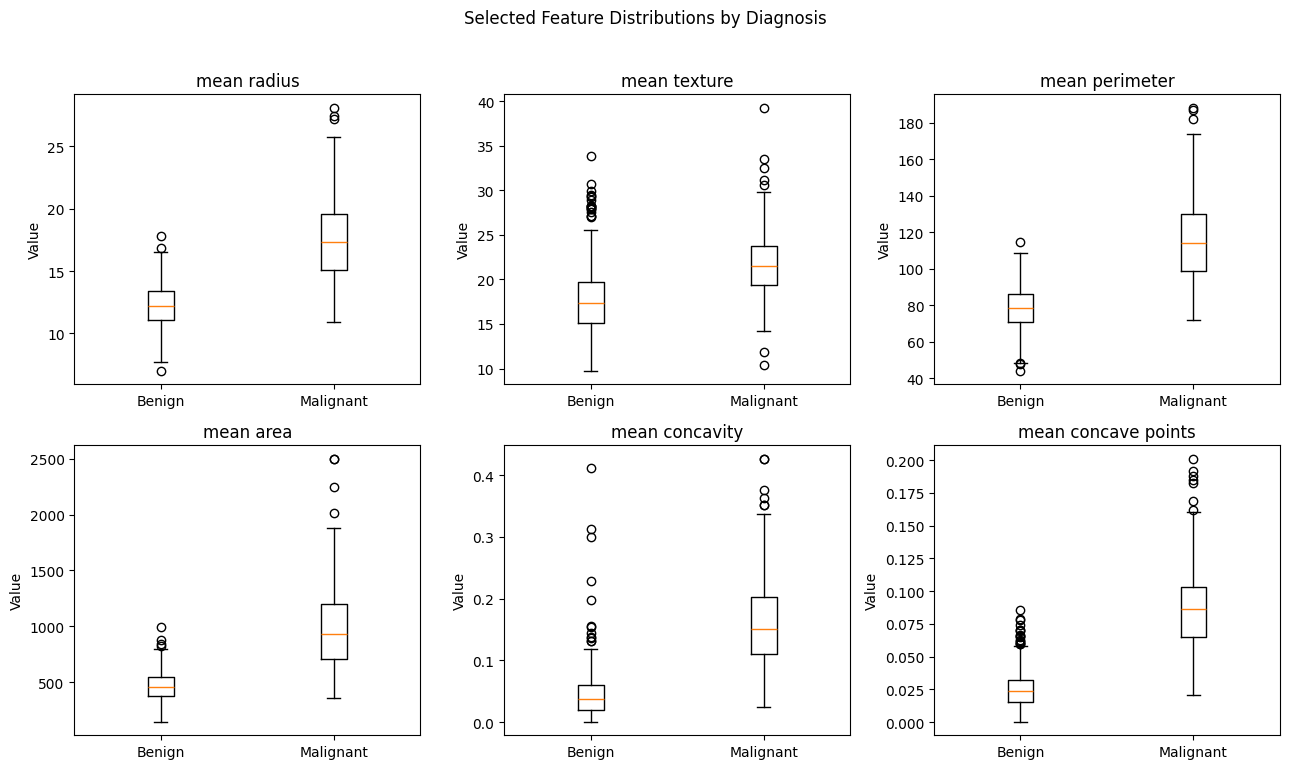

In [7]:
box_features = ["mean radius", "mean texture", "mean perimeter", "mean area",
                "mean concavity", "mean concave points"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, feature in zip(axes.ravel(), box_features):
    ax.boxplot([X.loc[y == 0, feature], X.loc[y == 1, feature]],
               tick_labels=["Benign", "Malignant"])
    ax.set_title(feature); ax.set_ylabel("Value")
fig.suptitle("Selected Feature Distributions by Diagnosis", y=1.02)
fig.tight_layout(); plt.show()

In [ ]:
## 8. EDA — correlation heatmap
Strong correlations among related measurements (such as radius, perimeter and area) may indicate overlapping information. Correlation does not imply causation.

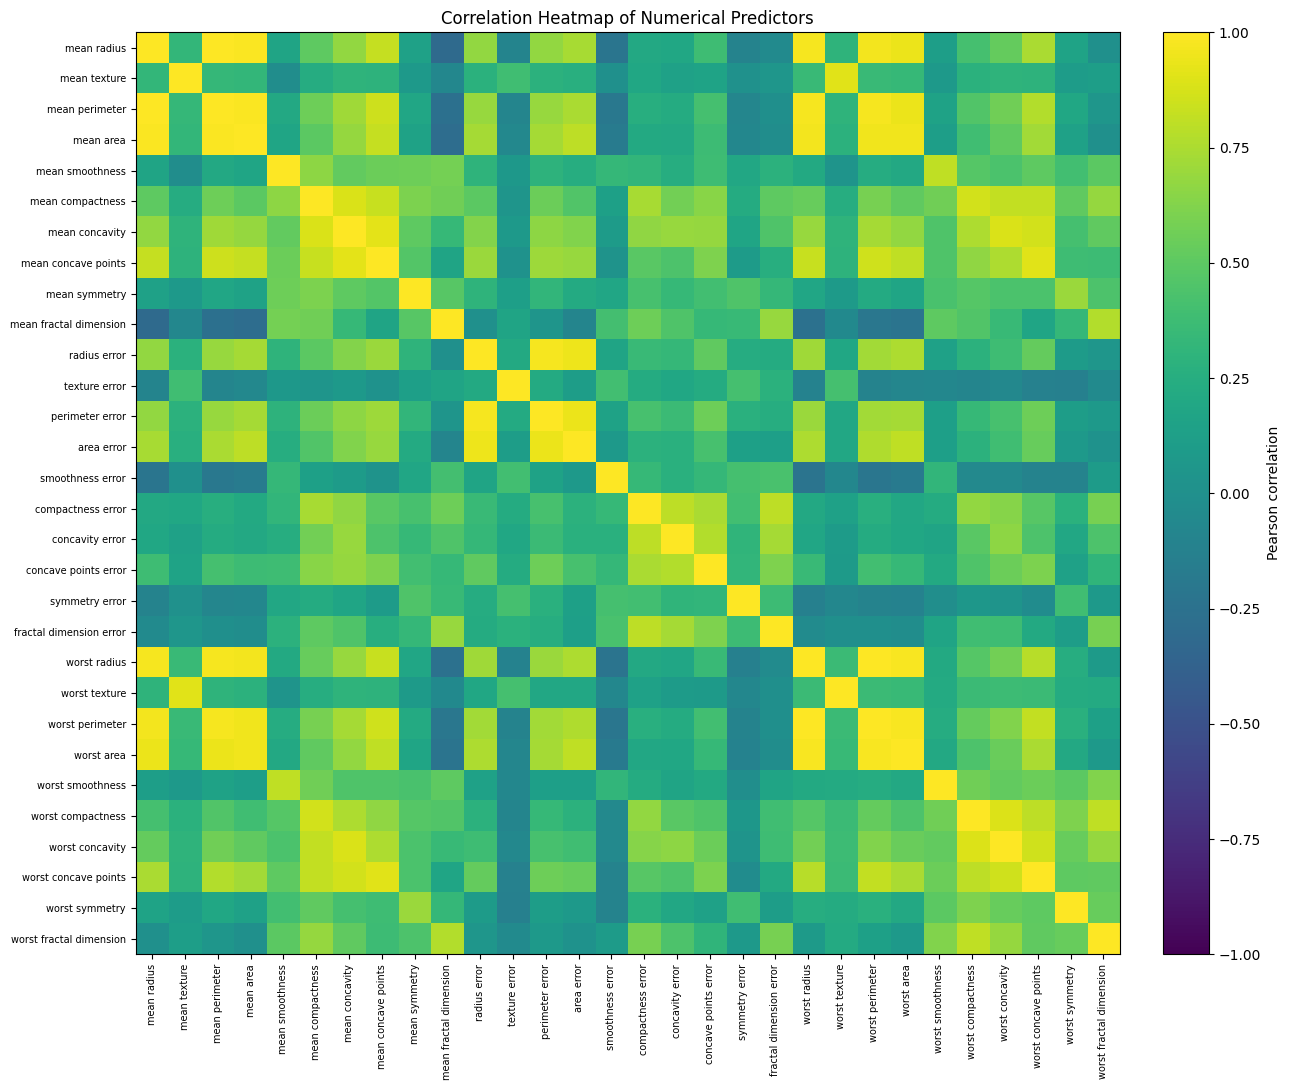

,correlation_with_malignant_target
worst concave points,0.794
worst perimeter,0.783
mean concave points,0.777
worst radius,0.776
mean perimeter,0.743
worst area,0.734
mean radius,0.730
mean area,0.709
mean concavity,0.696
worst concavity,0.660


In [8]:
correlation_matrix = X.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(correlation_matrix.values, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))
ax.set_xticklabels(correlation_matrix.columns, rotation=90, fontsize=7)
ax.set_yticklabels(correlation_matrix.columns, fontsize=7)
ax.set_title("Correlation Heatmap of Numerical Predictors")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
fig.tight_layout(); plt.show()
target_correlations = X.corrwith(y).sort_values(key=lambda s: s.abs(), ascending=False)
display(target_correlations.to_frame("correlation_with_malignant_target").round(3))
target_correlations.to_csv("part2_feature_target_correlations.csv")

In [ ]:
## 9. Split data
Use an 80:20 stratified split. Keep the test data separate from feature selection and hyperparameter tuning.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 455 | Test rows: 114


In [ ]:
## 10. Train baseline Random Forest

In [10]:
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
base_prob = baseline.predict_proba(X_test)[:, list(baseline.named_steps["model"].classes_).index(1)]

In [ ]:
## 11. Evaluation metrics
Accuracy measures overall correctness. Malignant recall measures how many actual malignant cases were identified. Precision, F1-score and ROC-AUC provide complementary information.

In [11]:
def evaluate(y_true, pred, prob):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision (malignant)": precision_score(y_true, pred, pos_label=1, zero_division=0),
        "Recall (malignant)": recall_score(y_true, pred, pos_label=1, zero_division=0),
        "F1 (malignant)": f1_score(y_true, pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob)
    }
base_metrics = evaluate(y_test, base_pred, base_prob)
display(pd.DataFrame([base_metrics], index=["Baseline Random Forest"]).round(4))
print(classification_report(y_test, base_pred, labels=[0,1],
      target_names=["Benign","Malignant"], digits=4, zero_division=0))

,Accuracy,Precision (malignant),Recall (malignant),F1 (malignant),ROC-AUC
Baseline Random Forest,0.9737,1.0,0.9286,0.963,0.9929


              precision    recall  f1-score   support

      Benign     0.9600    1.0000    0.9796        72
   Malignant     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



In [ ]:
## 12. Feature selection and hyperparameter tuning
Feature selection is placed inside the pipeline, so it is fitted within each cross-validation fold. Grid search optimises malignant-class recall.

In [12]:
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("selector", SelectFromModel(RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=1),
        threshold="median")),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE, class_weight="balanced", n_jobs=1))
])
# A compact grid keeps execution practical while still comparing model settings.
param_grid = {
    "selector__threshold": ["median", "mean"],
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10],
    "model__min_samples_split": [2],
    "model__min_samples_leaf": [1],
    "model__max_features": ["sqrt"]
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, param_grid, scoring="recall", cv=cv, n_jobs=1, refit=True)
search.fit(X_train, y_train)
improved = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best cross-validation malignant recall:", round(search.best_score_, 4))

Best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100, 'selector__threshold': 'mean'}
Best cross-validation malignant recall: 0.9179


In [ ]:
## 13. Evaluate tuned model on the held-out test set

In [13]:
tuned_pred = improved.predict(X_test)
tuned_prob = improved.predict_proba(X_test)[:, list(improved.named_steps["model"].classes_).index(1)]
tuned_metrics = evaluate(y_test, tuned_pred, tuned_prob)
comparison = pd.DataFrame([base_metrics, tuned_metrics],
    index=["Baseline Random Forest", "Tuned Random Forest"])
display(comparison.round(4))
comparison.to_csv("part2_model_metrics.csv")
print(classification_report(y_test, tuned_pred, labels=[0,1],
      target_names=["Benign","Malignant"], digits=4, zero_division=0))

,Accuracy,Precision (malignant),Recall (malignant),F1 (malignant),ROC-AUC
Baseline Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929
Tuned Random Forest,0.9561,0.9744,0.9048,0.9383,0.9931


              precision    recall  f1-score   support

      Benign     0.9467    0.9861    0.9660        72
   Malignant     0.9744    0.9048    0.9383        42

    accuracy                         0.9561       114
   macro avg     0.9605    0.9454    0.9521       114
weighted avg     0.9569    0.9561    0.9558       114



In [ ]:
## 14. Confusion matrix

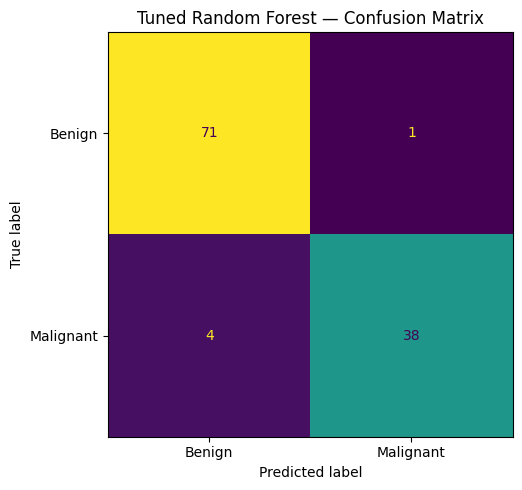

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, tuned_pred, labels=[0,1],
    display_labels=["Benign","Malignant"], colorbar=False, ax=ax)
ax.set_title("Tuned Random Forest — Confusion Matrix")
plt.tight_layout(); plt.show()

In [ ]:
## 15. ROC curve comparison

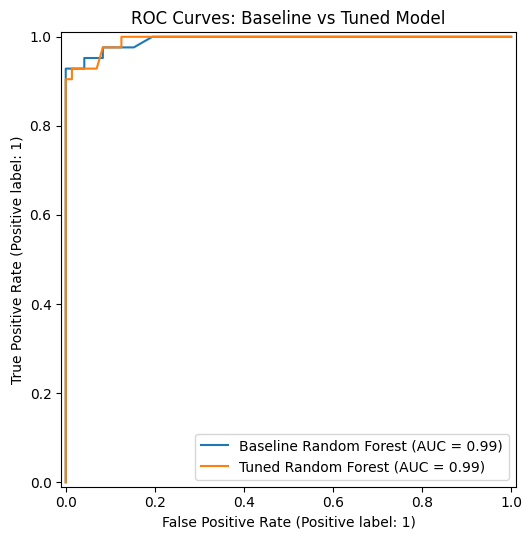

In [15]:
fig, ax = plt.subplots(figsize=(7, 5.5))
RocCurveDisplay.from_predictions(y_test, base_prob, name="Baseline Random Forest", ax=ax)
RocCurveDisplay.from_predictions(y_test, tuned_prob, name="Tuned Random Forest", ax=ax)
ax.set_title("ROC Curves: Baseline vs Tuned Model")
plt.tight_layout(); plt.show()

In [ ]:
## 16. Feature importance

Number of selected features: 11


,Feature,Importance
7,worst perimeter,0.2250
10,worst concave points,0.1726
4,mean concave points,0.1533
8,worst area,0.1375
6,worst radius,0.1348
3,mean concavity,0.0414
9,worst concavity,0.0350
5,area error,0.0270
1,mean perimeter,0.0261
2,mean area,0.0241


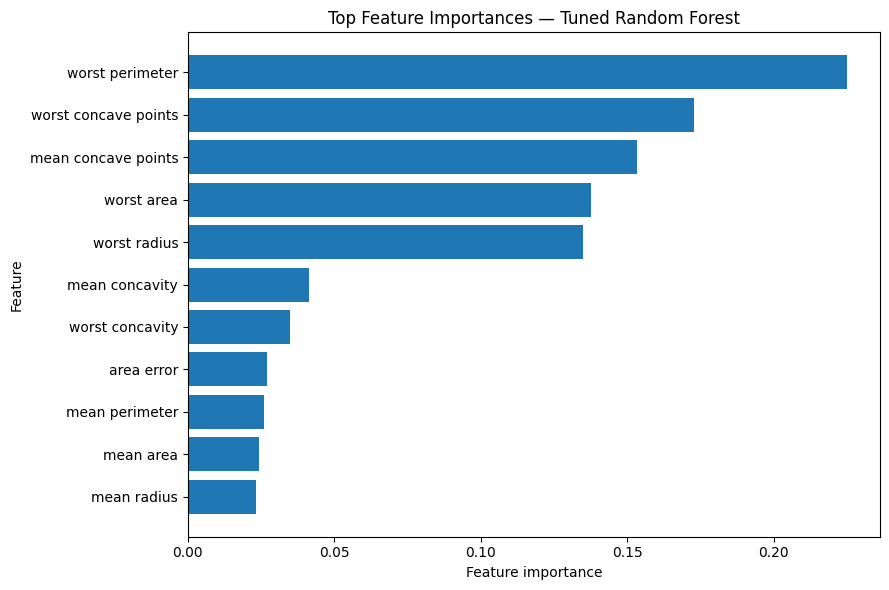

In [16]:
selected_features = X.columns[improved.named_steps["selector"].get_support()]
importance_table = pd.DataFrame({
    "Feature": selected_features,
    "Importance": improved.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)
print("Number of selected features:", len(selected_features))
display(importance_table.head(15).round(4))
top = importance_table.head(12).sort_values("Importance")
plt.figure(figsize=(9, 6))
plt.barh(top["Feature"], top["Importance"])
plt.title("Top Feature Importances — Tuned Random Forest")
plt.xlabel("Feature importance"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()
importance_table.to_csv("part2_feature_importance.csv", index=False)